In [2]:
def initialise_ionosphere_region(df, region):
    """ takes a dataframe of ionospheric properties and pulls the associated properties for a given region. making the necessary calculations required to run simulation CURRENTLY NOT ABLE TO HANDLE GEO"""

    # Pulls property name and values into a list and numpy array respectively
    value = df_ionosphere[region].to_numpy()
    properties = df_ionosphere["Properties"].to_list()

    # Creates a dictionary of the properties and values for the given region
    plasma_properties = dict(zip(properties, value))
    return plasma_properties


def normalised_plasma_potential(a, debye_length, mass_ratio, potential_radius=None):
    """Calculates the normalised plasma potential for a given debris radius, debye length, and mass ratio."""

    def eqn_surface_potential(x, mass_ratio, s, a):
        """Equation 32 from the NASA paper in the form 0 = f(x) where f(x) is equal to g(x) - A(1-B * e(Cx), this equation is then put through brents method to identify the roots of the function, eφ/kT"""
        return np.exp(x) - np.sqrt(mass_ratio) * (s / a) ** 2 * (
                    1 - ((s ** 2 - a ** 2) / s ** 2) * np.exp((a ** 2 / (s ** 2 - a ** 2)) * x))

    # If potential_radius is not provided, it defaults to the debye_length.
    if potential_radius is None:
        potential_radius = debye_length

    s = a + debye_length

    x_sol = brentq(eqn_surface_potential, -10, 0, args=(mass_ratio, s, a))
    phi_np = x_sol * np.exp(-potential_radius / debye_length)  # normalised plasma potential

    return phi_np


def forcing_term_general(np_potential, xi, tau, vd, G):
    return np_potential * np.exp(-1 * ((xi - (vd * tau)) / G) ** 2)


def ck_solver(last_sol, current_sol, alpha, beta, k, f, dt):
    """Use the Crank-Nicolson scheme to solve the normalised forced KdV equation on a non-periodic domain."""
    # pre-calculating coefficients
    _ck_beta = dt * beta * 1j * k ** 3  # removed s**3 term
    _ck_z = dt * 1j * k  # removed s term

    # computing the rfft of u & f halfs the length of array which then is multipled by 1024 leng coefficents arrays because of k
    _ck_beta_fft = _ck_beta[:len(k) // 2 + 1]  # Keep only first 513 elements
    _ck_z_fft = _ck_z[:len(k) // 2 + 1]

    # Fourier transform of the last solution, current solution, and forcing term
    fft_last = rfft(last_sol)
    fft_current_sqrd = rfft(current_sol ** 2)
    fft_f = rfft(f)

    return irfft(((1 - _ck_beta_fft) ** -1) * ((1 + _ck_beta_fft) * fft_last - alpha * _ck_z_fft * (fft_current_sqrd) + _ck_z_fft * fft_f))

## Imports & variables
import numpy as np
from numpy.fft import rfft, irfft
import pandas as pd
import matplotlib.pyplot as plt
from IPython.core.pylabtools import figsize
from scipy.optimize import brentq

df_ionosphere = pd.read_excel(r'Ionosphere prop.xltx') # Upload the Ionosphere properties from the Excel file
plasma_prop = initialise_ionosphere_region(df_ionosphere, "Low LEO") # Pulls the properties for the Low LEO region into a dictionary
display(df_ionosphere)

# Global constants
__kb__ = 1.380649e-23  #Boltzmann constant in J/K
__c__ = 299792458.0  # Speed of light in m/s
__me__ = 9.1093837139e-31  # Electron mass in kg
__mh__ = 1.67262192595e-27  # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27  # Oxygen ion mass in kg

# Normlaised units
TU = (plasma_prop["Debye Length"] * 1e-2) / (plasma_prop["Ion Acoustic Velocity"] * 1e3)  # Time unit in seconds
vd_norm = 1 / (plasma_prop["Ion Acoustic Velocity"] * 1e3)  # Normalised debris velocity

# ======================================= Inputs ====================================================

# physical parameters
a = 0.01  # debris in m
alpha = 6 # Nonlinearity parameter ( 1.0051)
beta = 1 # Dispersion parameter (0.4925)

# forcing parameters
vd = 1.20  # Debris velocity in km/s
np_potential = None  # Normalised plasma potential, if None, it will be automatically calculated.
G = a / (plasma_prop["Debye Length"] * 1e-2)  # Normalised forcing width

# Simulation parameters
N = 1024  # number of discretised points in the domain (power of 2 for FFT speed)
L = 50.0  # size of the domain
dtau = 1e-3  # TU
tau_inital = 0.0  # TU
tau_final =  1   # TU

# ======================================================================================================
# Determine the ion species and set the corresponding ion mass and mass ratio
if plasma_prop["Ion Species"] == "O":
    mi = __mo__
    mass_ratio = __me__ / __mo__
elif plasma_prop["Ion Species"] == "H":
    mi = __mh__
    mass_ratio = __me__ / __mh__
else:
    raise ValueError("Ion species not recognised. Please use 'O' for Oxygen or 'H' for Hydrogen.")

# if up
if np_potential is None:
    np_potential = normalised_plasma_potential(a, plasma_prop["Debye Length"], mass_ratio)


,Properties,Units,Low LEO,High LEO I,High LEO II,GEO
0,Altitude,km,700,1200,1400,35786
1,Latitude,deg,"0,50",0-55,0-55,0-90
2,Electron Density,cm^-3,200000,100000,10000,1
3,Electron Tempreture,eV,0.25,0.35,0.35,1000
4,Ion Species,NaN,O,H,H,OH
5,Ion Mass,proton mass,16,1,1,"16,1"
6,Debye Length,cm,0.83,1.38,4.36,23504
7,Debris Velocity Circular Orbit,km/s,7.51,7.26,7.16,3.08
8,Ion Acoustic Velocity,km/s,1.22,5.75,5.75,"77.43 , 309.73"


In [ ]:
## Running the Simulation
def run_simulation(a, L, N, t_inital, t_final, dt, alpha, beta, vd_norm, G, np_potential, analytical_sol, forcing_fn, num_stablising_steps=5, mode="rest", verbose=1):
    """Runs the simulation for the normalised forced KdV equation using the Crank-Nicolson scheme. The simulation can be run in two modes: 'rest' for starting from rest frame, and 'analyitcal' starting from some exact solution for the kdv equation. The function returns the solution array, time array, and mesh space."""

    x = np.linspace(-L, L, N, endpoint=False)  # Defining mesh space & wave numbers
    dx = x[1] - x[0]
    k = 2 * np.pi * np.fft.fftfreq(N, d=dx)

    if mode == "rest":
        num_steps = int(abs((t_inital + (dt / 10) * num_stablising_steps) - t_final) / dt) + num_stablising_steps + 2
    elif mode == "analytical":
        num_steps = int(abs(t_inital - t_final) / dt) + 2
    else:
        raise ValueError("Invalid mode. Please choose 'rest' or 'analytical'.")

    # Initialising the solution array and time array
    time_array = np.zeros(num_steps)
    sol = np.zeros((len(time_array), N))
    print(f"Number of time steps: {num_steps}")

    if mode == "rest":
        sol[0] = np.zeros(N)  # Initial condition is set to 0
        sol[1] = np.zeros(N)
        time_array[0] = 0
        time_array[1] = t_inital

    else:  # mode == "analytical"
        sol[0] = analytical_sol(a = a, x = x)  # Initial condition is set to the exact solution of the KdV equation
        sol[1] = analytical_sol(a = a, x = x)
        time_array[0] = -1 * dt  # Initial time step is set to t_inital - dt to account for the first step being a special case
        time_array[1] = 0

    step = 1  # Start from the second time step since the first two are already set
    sim_time = t_inital  # start
    while sim_time <= t_final:
        sim_dt = dt
        if mode == "rest" and step <= num_stablising_steps:
            sim_dt = dt/ 10

        forcing = forcing_fn(np_potential = np_potential, x = x, current_time = sim_time, vd_norm = vd_norm, G = G)

        sol[step + 1] = ck_solver(last_sol=sol[step - 1],  # Propogate exact solution forward in time with CK scheme
                                  current_sol=sol[step],
                                  alpha=alpha,
                                  beta=beta,
                                  k=k,
                                  f=forcing,
                                  dt=sim_dt
        )

        if step % verbose == 0:  # only prints every 10000 steps to avoid cluttering the output
            print(f"Time step: {step}, Time: {sim_time:.2f} TU")
            print(f"Max value of solution: {np.max(sol[step + 1]):.4f}, Min value of solution: {np.min(sol[step + 1]):.4f}")


        sim_time += sim_dt
        time_array[step + 1] = sim_time
        step += 1

    print("Simulation complete.")
    print(time_array[-1], sol[-1])
    return sol, time_array, x

In [3]:
def fkdv_exact_solution(a, x, K = 0.6124):
    return a / (np.cosh(K * x)**2)

def exact_n_solution(x = None, N = 3, a = None):
    return N * (N + 1) * (np.cosh(x)**(-2))

def unforced_solution(np_potential = None, x = None, current_time = None, vd_norm = None, G = None):
    return np.zeros_like(x)

1
Number of time steps: 1002
Time step: 1, Time: 0.00 TU
Max value of solution: 12.2120, Min value of solution: -0.0000
Time step: 2, Time: 0.00 TU
Max value of solution: 11.8726, Min value of solution: -0.0000
Time step: 3, Time: 0.00 TU
Max value of solution: 12.2850, Min value of solution: -0.0000
Time step: 4, Time: 0.00 TU
Max value of solution: 11.9878, Min value of solution: -0.0000
Time step: 5, Time: 0.00 TU
Max value of solution: 12.3245, Min value of solution: -0.0000
Time step: 6, Time: 0.01 TU
Max value of solution: 12.1553, Min value of solution: -0.0000
Time step: 7, Time: 0.01 TU
Max value of solution: 12.4561, Min value of solution: -0.0000
Time step: 8, Time: 0.01 TU
Max value of solution: 12.3549, Min value of solution: -0.0000
Time step: 9, Time: 0.01 TU
Max value of solution: 12.6398, Min value of solution: -0.0000
Time step: 10, Time: 0.01 TU
Max value of solution: 12.5952, Min value of solution: -0.0000
Time step: 11, Time: 0.01 TU
Max value of solution: 12.8746,

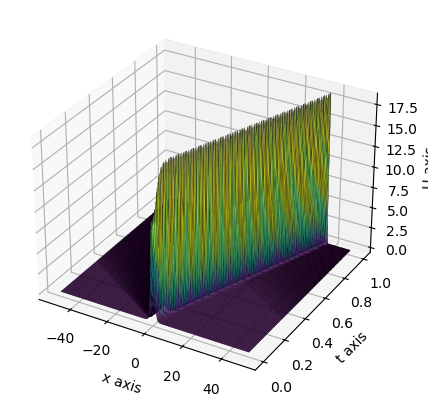

In [11]:
print(tau_final)
anal_sol, anal_time_array, anal_xi = run_simulation(a, L, N, tau_inital, tau_final, dtau, alpha, beta, vd_norm, G, np_potential,
                                                    exact_n_solution,
                                                    unforced_solution,
                                                    mode="analytical"
                                                    )

Xi, Tau = np.meshgrid(anal_xi, anal_time_array)  # Create meshgrid for plotting
fig = plt.figure(figsize=(6,5))
ax = plt.subplot(111, projection='3d')
ax.plot_surface(
    Xi,
    Tau,
    anal_sol,
    cmap="viridis",
    rstride=5,
    cstride=5,
    edgecolor="black",  # set edgecolours
    linewidth=0.1,      # set line width
    antialiased=True,
)

ax.set_xlabel('x axis')
ax.set_ylabel('t axis')
ax.set_zlabel('U axis')

#ax.view_init(elev=23, azim=100, roll=0)

plt.show()

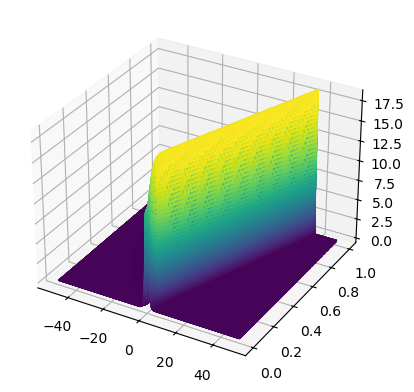

In [13]:
# Normalize to [0,1]
from matplotlib import cm

X = Xi
Y = Tau
Z = anal_sol

norm = plt.Normalize(Z.min(), Z.max())
colors = cm.viridis(norm(Z))
rcount, ccount, _ = colors.shape

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
surf = ax.plot_surface(X, Y, Z, rcount=rcount, ccount=ccount,
                       facecolors=colors, shade=False)
surf.set_facecolor((0,0,0,0))
plt.show()